---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Kelompok G13 Brownbear

- Wafiq Hibban Robbany (13524016)
- Moh. Hafizh Irham Perdana (13524025)
- Wildan Abdurrahman Ghazali (13524054)
- A. Fawwaz Azam Wicaksono (13524070)
- Zahran Alvan Putra Winarko (13524124)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pemesanan yang dibatalkan meninggalkan kamar kosong yang sebenarnya masih bisa dijual ke tamu lain. Jika pembatalan dapat diprediksi lebih awal, penginapan dapat merencanakan *overbooking*, mengirim pengingat, dan menyesuaikan kebijakan pembatalan.

## Aim

Kami membangun model klasifikasi yang memprediksi `is_canceled` (1 = batal, 0 = tidak batal). KNN, Decision Tree Learning, Logistic Regression, SVM, dan Naive Bayes diimplementasikan dari awal, dibandingkan dengan pasangan scikit-learn, lalu model terbaik dipakai untuk submisi Kaggle.

## Metric

Metrik utama adalah macro F1, yaitu rata-rata F1 kelas batal dan kelas tidak batal. Kedua kelas berbobot sama, sehingga ambang keputusan (*threshold*) juga disetel agar kelas batal yang lebih sedikit tidak terabaikan.

## Dataset

Data training berisi 27.373 pemesanan dengan 17 fitur dan target `is_canceled`, sedangkan data test berisi 6.844 pemesanan tanpa label. Fitur mencakup jumlah tamu, lama menginap, paket makan, kategori kamar, kanal pemesanan, harga per malam, dan riwayat tamu. Delapan kolom memiliki nilai kosong, dan ID pemesanan dipertahankan sebagai teks.

## Approach

1. Data diperiksa terlebih dahulu, lalu data training dibagi menjadi training dan validasi tanpa memisahkan baris fitur yang identik.
2. Setiap pipeline hanya di-fit pada bagian training, lalu dipakai untuk mentransformasi validasi dan test.
3. Kelima model dibandingkan pada validasi yang sama, kemudian model terbaik ditingkatkan lewat rekayasa fitur, pencarian bobot fitur, dan pemilihan threshold dengan 5-fold cross-validation.
4. Model akhir adalah KNN dengan jarak Manhattan berbobot ditambah penalti untuk atribut diskret yang berbeda. Pilihan ini didasarkan pada temuan bahwa banyak pemesanan memiliki "saudara" dengan label yang sama.
5. Model akhir dilatih ulang pada seluruh data training untuk submisi Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import pickle
import random
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

if (Path.cwd() / 'data/train.csv').is_file():
    os.chdir('src')
sys.path.insert(0, str(Path.cwd()))

from brownbear.models import KNN, SVM, DecisionTree, LogisticRegression, NaiveBayes
from brownbear.preprocessing import (
    BINARY_COLUMNS, CATEGORICAL_COLUMNS, FEATURE_COLUMNS, KNN_FEATURE_WEIGHTS, NUMERIC_COLUMNS,
    SIBLING_KEY, add_knn_features, impute_from_siblings, make_basic_preprocessor,
    make_discrete_preprocessor, make_knn_preprocessor, make_numeric_preprocessor,
    make_svm_preprocessor, select_features, split_training_data,
)

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('../data')
    OUTPUT_DIR = Path('../output')

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
description = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'unique': train_df.nunique(dropna=True),
    'missing': train_df.isna().sum(),
})
print(description)
print(train_df[NUMERIC_COLUMNS].describe().T)

                            dtype  unique  missing
id                            str   27373        0
num_adults                float64       5      809
num_children              float64       6     3035
weekend_nights              int64       8        0
weekday_nights              int64      18        0
meal_package                  str       4     1760
needs_parking             float64       2     1082
room_category                 str       7     1002
days_before_arrival       float64     407     1123
arrival_year                int64       2        0
arrival_month               int64      12        0
arrival_day                 int64      31        0
booking_channel               str       5        0
is_returning_guest          int64       2        0
prior_cancellations         int64       9        0
prior_completed_bookings    int64      52        0
nightly_rate_idr          float64    2787     2038
special_requests          float64       6     2500
is_canceled                 int

## Explore Data

This part covers distributions and relationships between attributes.

In [7]:
print(train_df['is_canceled'].value_counts().sort_index().rename('count').to_frame())
for column in CATEGORICAL_COLUMNS:
    print(column, train_df[column].value_counts(dropna=False).to_dict())

lead_bins = pd.cut(train_df['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
print(train_df.groupby(lead_bins, observed=True)['is_canceled'].agg(['size', 'mean']).round(3))
print(train_df.groupby('special_requests')['is_canceled'].agg(['size', 'mean']).round(3))

sibling_key = SIBLING_KEY + ['days_before_arrival', 'booking_channel', 'num_adults']
siblings = train_df.groupby(sibling_key)['is_canceled'].agg(['size', 'mean'])
shared = siblings[siblings['size'] > 1]
print('Pemesanan dalam kelompok saudara:', int(shared['size'].sum()))
print('Kelompok dengan label seragam:',
      round(shared.loc[shared['mean'].isin([0, 1]), 'size'].sum() / shared['size'].sum(), 3))
print('Data test yang punya saudara persis di training:',
      round(test_df[sibling_key].merge(siblings.reset_index(), on=sibling_key, how='left')['size'].notna().mean(), 3))

             count
is_canceled       
0            18404
1             8969
meal_package {'Breakfast': 19654, 'Room Only': 3713, 'Half Board': 2242, nan: 1760, 'Full Board': 4}
room_category {'Type B': 20447, 'Type G': 4396, nan: 1002, 'Type A': 699, 'Type D': 514, 'Type C': 189, 'Type F': 119, 'Type E': 7}
booking_channel {'Online Travel Agent': 17511, 'Offline Agent': 7960, 'Corporate': 1513, 'Complimentary': 301, 'Airline': 88}
                     size   mean
days_before_arrival             
(-1, 7]              4116  0.096
(7, 30]              4868  0.183
(30, 90]             7847  0.253
(90, 180]            5573  0.451
(180, 500]           3846  0.736
                   size   mean
special_requests              
0.0               12730  0.432
1.0                8334  0.238
2.0                3246  0.143
3.0                 496  0.000
4.0                  60  0.000
5.0                   7  0.000
Pemesanan dalam kelompok saudara: 5658
Kelompok dengan label seragam: 0.862
Data test 

Pembatalan meningkat tajam seiring bertambahnya `days_before_arrival`, sedangkan pemesanan dengan permintaan khusus lebih jarang batal. Selain itu, banyak pemesanan memiliki "saudara", yaitu pemesanan lain dengan tanggal kedatangan, lama menginap, kanal, dan jumlah dewasa yang sama. Sekitar 86% kelompok saudara memiliki label seragam. `days_before_arrival` dan harga di antara saudara sering sedikit berbeda, sehingga pencocokan persis meremehkan jumlah saudara yang sebenarnya. Pola lokal ini menjadi alasan utama kami mengembangkan KNN.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
raw_train = select_features(train_df)
raw_test = select_features(test_df)
quality = pd.DataFrame(index=FEATURE_COLUMNS)
quality['train_missing'] = raw_train.isna().sum()
quality['train_missing_pct'] = raw_train.isna().mean().mul(100)
quality['test_missing'] = raw_test.isna().sum()
quality['test_missing_pct'] = raw_test.isna().mean().mul(100)
print(quality.loc[quality[['train_missing', 'test_missing']].sum(axis=1) > 0].round(2))
print('Nilai dan tanggal kedatangan lolos validasi.')

                     train_missing  train_missing_pct  test_missing  \
num_adults                     809               2.96           180   
num_children                  3035              11.09           747   
days_before_arrival           1123               4.10           290   
nightly_rate_idr              2038               7.45           540   
special_requests              2500               9.13           593   
needs_parking                 1082               3.95           247   
meal_package                  1760               6.43           442   
room_category                 1002               3.66           242   

                     test_missing_pct  
num_adults                       2.63  
num_children                    10.91  
days_before_arrival              4.24  
nightly_rate_idr                 7.89  
special_requests                 8.66  
needs_parking                    3.61  
meal_package                     6.46  
room_category                    3.54  


Delapan fitur memiliki nilai kosong pada data latih dan data uji. Karena target tersedia hanya pada data latih, data uji disimpan khusus untuk submission.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
train_idx, val_idx = split_training_data(train_df, seed=CFG.SEED)
train_set, val_set = train_df.iloc[train_idx].copy(), train_df.iloc[val_idx].copy()
groups = raw_train.groupby(FEATURE_COLUMNS, dropna=False, sort=False).ngroup()
assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[val_idx])
assert sorted(np.r_[train_idx, val_idx]) == list(range(len(train_df)))
assert set(train_set['is_canceled']) == set(val_set['is_canceled']) == {0, 1}
split_summary = pd.DataFrame({
    name: {'rows': len(frame), 'canceled': int(frame['is_canceled'].sum()),
           'canceled_pct': frame['is_canceled'].mean() * 100}
    for name, frame in [('training', train_set), ('validation', val_set)]
}).T
print(split_summary.round(3))

               rows  canceled  canceled_pct
training    21899.0    7175.0        32.764
validation   5474.0    1794.0        32.773


Proporsi pembatalan hampir sama pada kedua bagian data. Pemisahan berdasarkan kelompok fitur juga mencegah baris yang identik berpindah ke validasi.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
X_train_raw, X_val_raw = select_features(train_set), select_features(val_set)
y_train = train_set['is_canceled'].astype(int)
y_val = val_set['is_canceled'].astype(int)
test_ids = test_df['id'].copy()
assert not X_train_raw.isna().all().any(), 'Ada fitur yang seluruhnya kosong.'
print('Ketujuh belas fitur dipakai; ID dan target disimpan terpisah.')

Ketujuh belas fitur dipakai; ID dan target disimpan terpisah.


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
prep = make_basic_preprocessor()
X_train = prep.fit_transform(X_train_raw)
X_val = prep.transform(X_val_raw)
X_test = prep.transform(raw_test)
imputer = prep.named_steps['impute']
fills = pd.DataFrame({'feature': NUMERIC_COLUMNS + BINARY_COLUMNS,
                     'strategy': ['median'] * len(NUMERIC_COLUMNS) + ['mode'] * len(BINARY_COLUMNS),
                     'value': np.r_[imputer.named_transformers_['numeric'].statistics_,
                                    imputer.named_transformers_['binary'].statistics_]})
print(fills)
print('Nilai kosong setelah preprocessing:', {name: int(frame.isna().sum().sum())
      for name, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]})

rng = np.random.default_rng(CFG.SEED)
known_lead = X_train_raw.index[X_train_raw['days_before_arrival'].notna()]
hidden = rng.choice(known_lead, 1000, replace=False)
probe = X_train_raw.loc[hidden].assign(days_before_arrival=np.nan)
truth = X_train_raw.loc[hidden, 'days_before_arrival']
sibling_guess = impute_from_siblings(X_train_raw.drop(hidden), probe)
median_guess = X_train_raw.drop(hidden)['days_before_arrival'].median()
print('MAE imputasi days_before_arrival dari saudara:', round((sibling_guess - truth).abs().mean(), 1), 'hari')
print('MAE imputasi days_before_arrival dari median :', round((median_guess - truth).abs().mean(), 1), 'hari')

                     feature strategy      value
0                 num_adults   median        2.0
1               num_children   median        0.0
2             weekend_nights   median        1.0
3             weekday_nights   median        2.0
4        days_before_arrival   median       58.0
5               arrival_year   median     2024.0
6              arrival_month   median        8.0
7                arrival_day   median       16.0
8        prior_cancellations   median        0.0
9   prior_completed_bookings   median        0.0
10          nightly_rate_idr   median  1648000.0
11          special_requests   median        0.0
12             needs_parking     mode        0.0
13        is_returning_guest     mode        0.0
Nilai kosong setelah preprocessing: {'train': 0, 'validation': 0, 'test': 0}


MAE imputasi days_before_arrival dari saudara: 29.9 hari
MAE imputasi days_before_arrival dari median : 61.6 hari


Nilai numerik diisi dengan median, sedangkan penanda biner diisi dengan modus. Kategori yang kosong diberi label khusus agar tetap dapat dibedakan. Semua nilai pengganti dihitung dari data training saja.

Khusus untuk KNN, `days_before_arrival` yang kosong diisi dari pemesanan saudara paling mirip di data training, yaitu pemesanan dengan tanggal kedatangan dan lama menginap yang sama. Uji dengan 1.000 nilai yang sengaja disembunyikan menunjukkan galat imputasi ini sekitar setengah dari galat imputasi median. Pada penalti jarak KNN, nilai kosong tidak dianggap berbeda sehingga baris tersebut tidak dihukum dua kali.

### Duplicates

This part covers repeated records.

In [12]:
duplicate_summary = {
    'repeated_ids_train': int(train_df['id'].duplicated().sum()),
    'repeated_records_excluding_id': int(train_df.drop(columns='id').duplicated().sum()),
    'repeated_feature_rows': int(raw_train.duplicated().sum()),
    'conflicting_feature_groups': int(train_df.groupby(
        FEATURE_COLUMNS, dropna=False)['is_canceled'].nunique().gt(1).sum()),
    'shared_raw_groups_train_val': len(set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])),
}
print(duplicate_summary)
print('Baris fitur yang berulang tetap disimpan sebagai pemesanan terpisah.')

{'repeated_ids_train': 0, 'repeated_records_excluding_id': 64, 'repeated_feature_rows': 66, 'conflicting_feature_groups': 2, 'shared_raw_groups_train_val': 0}
Baris fitur yang berulang tetap disimpan sebagai pemesanan terpisah.


Semua ID pemesanan berbeda, tetapi beberapa baris fitur memang berulang. Baris tersebut tetap disimpan karena dua kelompok fitur bahkan memiliki label yang berbeda.

### Outliers

This part covers values far from the rest of the data.

                             median         p99        max    skew       iqr  \
num_adults                      2.0        3.00        4.0  -0.312       0.0   
num_children                    0.0        2.00       10.0   4.902       0.0   
weekend_nights                  1.0        2.02        7.0   0.763       2.0   
weekday_nights                  2.0        6.00       17.0   1.685       2.0   
days_before_arrival            58.0      345.00      448.0   1.302     110.0   
arrival_year                 2024.0     2024.00     2024.0  -1.662       0.0   
arrival_month                   8.0       12.00       12.0  -0.349       5.0   
arrival_day                    16.0       31.00       31.0   0.036      15.0   
prior_cancellations             0.0        0.00       13.0  26.059       0.0   
prior_completed_bookings        0.0        4.00       58.0  20.416       0.0   
nightly_rate_idr          1648000.0  3456350.00  6338000.0   0.587  683000.0   
special_requests                0.0     

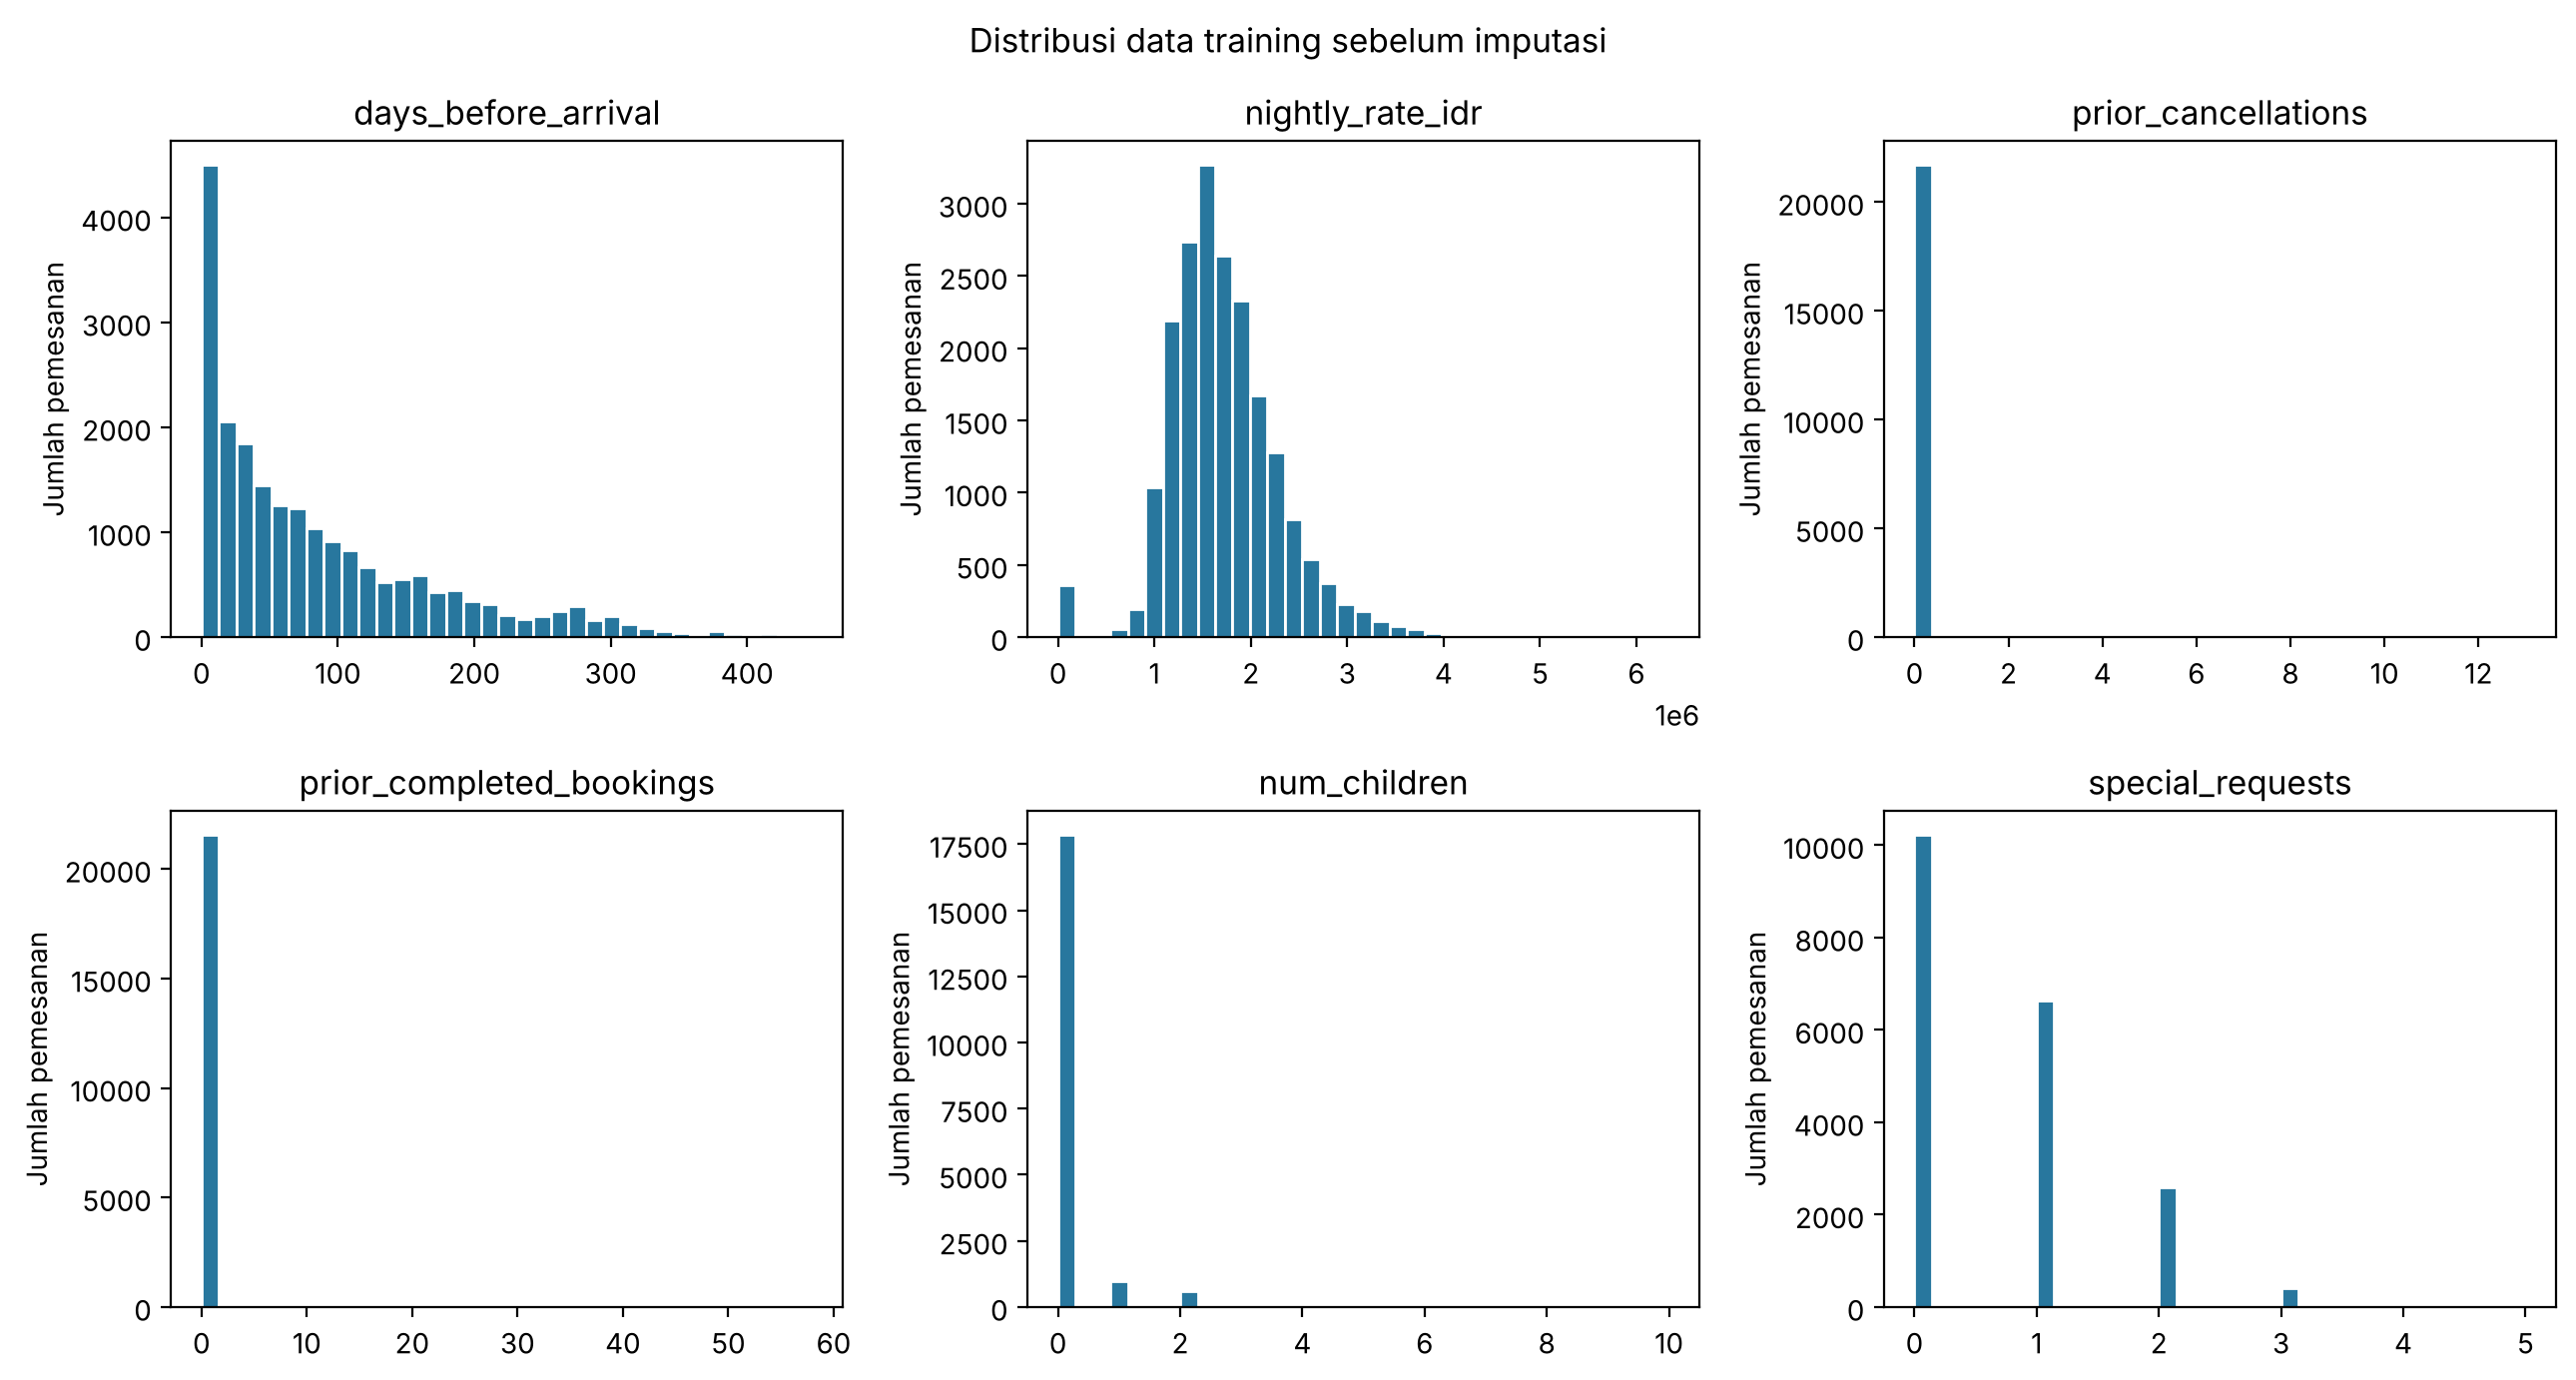

In [13]:
numeric = X_train_raw[NUMERIC_COLUMNS]
q1, q3 = numeric.quantile(.25), numeric.quantile(.75)
iqr = q3 - q1
outlier_review = pd.DataFrame({'median': numeric.median(), 'p99': numeric.quantile(.99),
                              'max': numeric.max(), 'skew': numeric.skew(), 'iqr': iqr,
                              'zero_pct': numeric.eq(0).sum() / numeric.notna().sum() * 100,
                              'outside_iqr': ((numeric < q1 - 1.5 * iqr) |
                                              (numeric > q3 + 1.5 * iqr)).sum()})
print(outlier_review.round(3))
plot_columns = ['days_before_arrival', 'nightly_rate_idr', 'prior_cancellations',
                'prior_completed_bookings', 'num_children', 'special_requests']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for column, ax in zip(plot_columns, axes.flat):
    ax.hist(numeric[column].dropna(), bins=35, color='#28779e', edgecolor='white')
    ax.set_title(column)
    ax.set_ylabel('Jumlah pemesanan')
fig.suptitle('Distribusi data training sebelum imputasi')
fig.tight_layout()
plt.show()

Aturan IQR menandai banyak nilai nol pada beberapa fitur hitungan. Nilai tersebut masih masuk akal, sehingga kami tidak menghapus baris hanya karena melewati batas IQR.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
audit_counts = {}
for name, frame in [('training', X_train_raw), ('validation', X_val_raw), ('test', raw_test)]:
    audit_counts[name] = {
        'zero_rate': int(frame['nightly_rate_idr'].eq(0).sum()),
        'zero_total_nights': int((frame['weekend_nights'] + frame['weekday_nights']).eq(0).sum()),
        'known_zero_total_guests': int((frame['num_adults'] + frame['num_children']).eq(0).sum()),
    }
print(pd.DataFrame(audit_counts).T)
print('Harga nol dan masa inap nol tetap dipertahankan.')

            zero_rate  zero_total_nights  known_zero_total_guests
training          330                 56                        0
validation         83                  8                        0
test               85                  9                        0
Harga nol dan masa inap nol tetap dipertahankan.


Harga nol dan masa inap nol ditemukan pada sebagian pemesanan. Nilai tersebut dipertahankan karena tidak ada bukti bahwa semuanya merupakan kesalahan pencatatan.

## Construct Data

Construction derives attributes and transforms values for modeling.

<!-- rubric v3: derived columns, rate_per_guest_night -->

### Attribute Construction

This part covers new attributes derived from existing ones.

In [15]:
knn_features = add_knn_features(X_train_raw)
derived_columns = ['month_sin', 'month_cos', 'log_lead', 'booking_ordinal', 'log_rate']
print(knn_features[derived_columns].describe().T.round(3))
booking_bins = pd.qcut(knn_features['booking_ordinal'], 5)
print(y_train.groupby(booking_bins, observed=True).mean().rename('canceled_rate').round(3))

                   count     mean      std   min      25%      50%      75%  \
month_sin        21899.0   -0.206    0.705  -1.0   -0.866   -0.500    0.500   
month_cos        21899.0   -0.036    0.677  -1.0   -0.500   -0.000    0.500   
log_lead         20998.0    3.729    1.486   0.0    2.890    4.078    4.852   
booking_ordinal  20998.0  422.914  146.343 -81.0  337.000  416.000  527.000   
log_rate         20254.0   14.092    1.843   0.0   14.109   14.315   14.521   

                     max  
month_sin          1.000  
month_cos          1.000  
log_lead           6.107  
booking_ordinal  727.000  
log_rate          15.662  
booking_ordinal
(-81.001, 296.0]    0.299
(296.0, 390.0]      0.400
(390.0, 454.0]      0.410
(454.0, 561.0]      0.338
(561.0, 727.0]      0.191
Name: canceled_rate, dtype: float64


Matriks dasar tetap memakai tujuh belas fitur asli. Untuk SVM dan KNN, kami menambahkan fitur turunan dari tanggal kedatangan, lama pemesanan, dan harga:

- `booking_ordinal` adalah tanggal pemesanan, yaitu tanggal kedatangan dikurangi `days_before_arrival`. Pemesanan rombongan biasanya dibuat pada hari yang sama, sehingga fitur ini membantu KNN menemukan pemesanan saudara.
- `month_sin` dan `month_cos` membuat bulan bersifat siklikal, sehingga Desember berdekatan dengan Januari.
- `log_lead` dan `log_rate` meredam kemiringan distribusi lama pemesanan dan harga.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
print(X_train[NUMERIC_COLUMNS + BINARY_COLUMNS].agg(['min', 'max']).T)

                             min        max
num_adults                   0.0        4.0
num_children                 0.0       10.0
weekend_nights               0.0        7.0
weekday_nights               0.0       17.0
days_before_arrival          0.0      448.0
arrival_year              2023.0     2024.0
arrival_month                1.0       12.0
arrival_day                  1.0       31.0
prior_cancellations          0.0       13.0
prior_completed_bookings     0.0       58.0
nightly_rate_idr             0.0  6338000.0
special_requests             0.0        5.0
needs_parking                0.0        1.0
is_returning_guest           0.0        1.0


Rentang harga jauh lebih besar daripada rentang fitur hitungan. Karena itu, pipeline numerik dan SVM melakukan standardisasi sebelum menghitung jarak atau margin.

### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
category_tables = []
for column in CATEGORICAL_COLUMNS:
    table = X_train.assign(is_canceled=y_train).groupby(column)['is_canceled'].agg(
        count='size', canceled_rate='mean').reset_index().rename(columns={column: 'category'})
    table.insert(0, 'feature', column)
    category_tables.append(table)
category_review = pd.concat(category_tables, ignore_index=True)
print(category_review.round(4))
unseen_categories = {column: {
    name: sorted(set(frame[column]) - set(X_train[column]))
    for name, frame in [('validation', X_val), ('test', X_test)]}
    for column in CATEGORICAL_COLUMNS}
print('Categories unseen during fitting:', unseen_categories)

            feature             category  count  canceled_rate
0      meal_package            Breakfast  15725         0.3124
1      meal_package           Full Board      4         0.2500
2      meal_package           Half Board   1793         0.4568
3      meal_package              MISSING   1404         0.3127
4      meal_package            Room Only   2973         0.3374
5     room_category              MISSING    797         0.3501
6     room_category               Type A    564         0.4255
7     room_category               Type B  16365         0.3218
8     room_category               Type C    161         0.2609
9     room_category               Type D    406         0.3325
10    room_category               Type E      6         0.1667
11    room_category               Type F     97         0.2577
12    room_category               Type G   3503         0.3389
13  booking_channel              Airline     72         0.3056
14  booking_channel        Complimentary    236        

Kategori nominal diubah menjadi kolom one-hot untuk model numerik. Naive Bayes memakai kode kategori diskret, sedangkan pohon keputusan membaca kategori asli. KNN memakai keduanya: kolom one-hot ikut dihitung dalam jarak Manhattan, sedangkan kode kategori dipakai untuk penalti saat kategori dua pemesanan berbeda.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [18]:
corr = X_train[NUMERIC_COLUMNS + BINARY_COLUMNS].corr()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
correlation_review = pairs.rename('pearson_r').reset_index()
correlation_review.columns = ['feature_1', 'feature_2', 'pearson_r']
correlation_review = correlation_review.sort_values('pearson_r', key=lambda s: s.abs(), ascending=False)
print(correlation_review.head(10).round(4))
numeric_by_class = X_train.assign(is_canceled=y_train).groupby('is_canceled')[NUMERIC_COLUMNS].median().T
print(numeric_by_class)

dropped = [column for column in knn_features.columns if column not in KNN_FEATURE_WEIGHTS]
print(f'Fitur KNN yang dipakai: {len(KNN_FEATURE_WEIGHTS)} dari {knn_features.shape[1]}')
print('Fitur dengan bobot 0:', dropped)

                    feature_1                 feature_2  pearson_r
139  prior_completed_bookings        is_returning_guest     0.5388
121       prior_cancellations  prior_completed_bookings     0.4669
125       prior_cancellations        is_returning_guest     0.3841
76               arrival_year             arrival_month    -0.3427
24               num_children          nightly_rate_idr     0.3115
10                 num_adults          nightly_rate_idr     0.2897
31             weekend_nights            weekday_nights     0.1893
13                 num_adults        is_returning_guest    -0.1884
11                 num_adults          special_requests     0.1834
151          nightly_rate_idr          special_requests     0.1792
is_canceled                       0          1
num_adults                      2.0        2.0
num_children                    0.0        0.0
weekend_nights                  1.0        1.0
weekday_nights                  2.0        2.0
days_before_arrival         

Beberapa fitur saling berkorelasi, tetapi jumlah fitur hasil encoding masih kecil. Kami tidak memakai PCA karena PCA mencampur fitur dan merusak struktur pemesanan saudara yang dimanfaatkan KNN. Sebagai gantinya, setiap fitur KNN diberi bobot hasil pencarian pada 5-fold cross-validation (lihat bagian *Improvements*). Fitur yang bobotnya 0, misalnya sebagian kolom one-hot dan `num_children`, otomatis tidak dipakai dalam perhitungan jarak.

## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
majority = int(y_train.mode().iloc[0])
baseline_pred = np.full(len(y_val), majority)
baseline = {'majority_class': majority,
            'validation_macro_f1': f1_score(y_val, baseline_pred, average='macro', labels=[0, 1], zero_division=0),
            'validation_accuracy': accuracy_score(y_val, baseline_pred)}
print(split_summary.round(3))
print(baseline)

               rows  canceled  canceled_pct
training    21899.0    7175.0        32.764
validation   5474.0    1794.0        32.773
{'majority_class': 0, 'validation_macro_f1': 0.4020100502512563, 'validation_accuracy': 0.6722689075630253}


Kelas tidak seimbang sempurna, sehingga akurasi saja kurang cukup untuk evaluasi. Macro F1 memberi bobot yang sama pada kedua kelas saat membandingkan model. Kami tidak melakukan *resampling* karena oversampling mengubah kepadatan tetangga pada KNN. Ketidakseimbangan ditangani dengan memilih threshold yang memaksimalkan macro F1.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
for clean, raw in [(X_train, X_train_raw), (X_val, X_val_raw), (X_test, raw_test)]:
    assert clean.shape == raw.shape
    assert clean.columns.tolist() == FEATURE_COLUMNS
    assert clean.index.equals(raw.index)
    assert not clean.isna().any().any()
    assert np.isfinite(clean[NUMERIC_COLUMNS + BINARY_COLUMNS].to_numpy()).all()
    for column in NUMERIC_COLUMNS + BINARY_COLUMNS:
        known = raw[column].notna()
        np.testing.assert_array_equal(clean.loc[known, column], raw.loc[known, column])
assert set(X_train.columns).isdisjoint({'id', 'is_canceled'})
print('Lolos: skema, urutan baris, nilai teramati, dan nilai kosong')

Lolos: skema, urutan baris, nilai teramati, dan nilai kosong


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
numeric_prep = make_numeric_preprocessor().fit(train_set)
nb_prep = make_discrete_preprocessor(n_bins=5).fit(train_set)
knn_prep = make_knn_preprocessor().fit(train_set)
X_train_numeric, X_val_numeric = numeric_prep.transform(train_set), numeric_prep.transform(val_set)
X_train_nb, X_val_nb = nb_prep.transform(train_set), nb_prep.transform(val_set)
X_train_knn, X_val_knn = knn_prep.transform(train_set), knn_prep.transform(val_set)
assert X_train_numeric.shape[0] == X_train_nb.shape[0] == X_train_knn.shape[0] == len(train_set)
assert X_val_numeric.shape[0] == X_val_nb.shape[0] == X_val_knn.shape[0] == len(val_set)
assert np.isfinite(X_val_numeric).all() and (X_val_nb >= 0).all()
assert np.isfinite(X_val_knn[:, :len(knn_prep.columns_)]).all()
print('Basic:', X_train.shape, X_val.shape, X_test.shape)
print('Numeric:', X_train_numeric.shape, X_val_numeric.shape)
print('Categorical NB:', X_train_nb.shape, X_val_nb.shape)
print('KNN:', X_train_knn.shape, X_val_knn.shape)

Basic: (21899, 17) (5474, 17) (6844, 17)
Numeric: (21899, 32) (5474, 32)
Categorical NB: (21899, 17) (5474, 17)
KNN: (21899, 39) (5474, 39)


Pipeline menggabungkan tahap persiapan agar semua model menerima data yang sudah ditransformasi secara konsisten. Pipeline numerik, Naive Bayes, dan KNN di-fit pada training saja. Ketiganya menghasilkan format yang berbeda karena kebutuhan masukan setiap model memang berbeda.

Matriks KNN terdiri atas dua bagian. Bagian pertama berisi fitur yang telah diimputasi, distandardisasi, dan dikalikan bobotnya untuk jarak Manhattan. Bagian kedua berisi nilai mentah untuk penalti: tanggal kedatangan, jumlah malam, jumlah tamu, kamar, paket makan, permintaan khusus, parkir, `days_before_arrival`, dan log harga. Nilai kosong pada bagian kedua tetap NaN.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

Perbandingan awal memakai lima ribu baris training yang dipilih secara stratifikasi. Seluruh baris validasi tetap dipakai agar penilaian setiap model konsisten. Setelah model dipilih, pelatihan akhir memakai seluruh data berlabel.

In [22]:
model_rows, _ = train_test_split(
    np.arange(len(train_set)), train_size=5000,
    stratify=y_train, random_state=CFG.SEED,
)
y_model = y_train.iloc[model_rows].to_numpy()
y_valid = y_val.to_numpy()
svm_prep = make_svm_preprocessor().fit(train_set)
model_inputs = {
    'numeric': (X_train_numeric[model_rows], X_val_numeric),
    'tree': (X_train_raw.iloc[model_rows], X_val_raw),
    'nb': (X_train_nb[model_rows], X_val_nb),
    'svm': (svm_prep.transform(train_set.iloc[model_rows]),
            svm_prep.transform(val_set)),
    'knn': (X_train_knn[model_rows], X_val_knn),
}
knn_params = dict(k=25, metric='manhattan', weights='distance', vote_power=1.5,
                  mismatch_groups=knn_prep.mismatch_groups_, tolerances=knn_prep.tolerances_)
model_factories = {
    'KNN': ('knn', lambda: KNN(**knn_params)),
    'CART': ('tree', lambda: DecisionTree(max_depth=10, min_samples_leaf=20)),
    'LogReg L1': ('numeric', lambda: LogisticRegression(
        penalty='l1', reg_strength=.01, max_iter=2000, tol=1e-5)),
    'LogReg L2': ('numeric', lambda: LogisticRegression(
        penalty='l2', reg_strength=.01, max_iter=2000, tol=1e-5)),
    'LogReg Elastic Net': ('numeric', lambda: LogisticRegression(
        penalty='elasticnet', reg_strength=.01, l1_ratio=.5,
        max_iter=2000, tol=1e-5)),
    'SVM Linear': ('svm', lambda: SVM(kernel='linear', C=1, max_iter=100_000)),
    'SVM Polynomial': ('svm', lambda: SVM(
        kernel='polynomial', C=1, degree=3, gamma=.1, coef0=1,
        max_iter=100_000)),
    'SVM Gaussian': ('svm', lambda: SVM(
        kernel='gaussian', C=3, gamma=.1, class_weight={1: 1.3},
        max_iter=100_000)),
    'Naive Bayes': ('nb', lambda: NaiveBayes(alpha=1)),
}
models, predictions, results = {}, {}, []

def evaluate(name):
    kind, factory = model_factories[name]
    X_fit, X_eval = model_inputs[kind]
    model = factory()
    start = perf_counter()
    model.fit(X_fit, y_model)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    predicted = model.predict(X_eval)
    predict_seconds = perf_counter() - start
    models[name], predictions[name] = model, predicted
    score = {
        'model': name,
        'macro_f1': f1_score(y_valid, predicted, average='macro'),
        'accuracy': accuracy_score(y_valid, predicted),
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    }
    results.append(score)
    print(name, {key: round(value, 4) if isinstance(value, float) else value
                 for key, value in score.items() if key != 'model'})

print('Baris training untuk perbandingan:', len(model_rows))
print('Baris validasi untuk perbandingan:', len(y_valid))

Baris training untuk perbandingan: 5000
Baris validasi untuk perbandingan: 5474


<!-- rubric v3: pairwise distances, val_neighbor_dists -->

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [23]:
evaluate('KNN')

KNN {'macro_f1': 0.8324, 'accuracy': 0.8566, 'fit_seconds': 0.001, 'predict_seconds': 4.7913}


KNN kami menghitung jarak Manhattan pada fitur berbobot, lalu menambahkan penalti jika tanggal kedatangan, jumlah malam, jumlah tamu, kamar, paket makan, permintaan khusus, atau parkir berbeda. Penalti juga ditambahkan jika selisih `days_before_arrival` lebih dari 15 hari atau selisih harga lebih dari sekitar 5%. Dengan cara ini, pemesanan saudara menjadi tetangga terdekat walaupun lead time dan harganya sedikit berbeda. Suara 25 tetangga dibobot dengan kebalikan jarak berpangkat 1,5. Pada tahap ini KNN hanya melihat 5.000 baris training, sama seperti model lain, sehingga skornya belum mencerminkan performa akhir.

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [24]:
evaluate('CART')

CART {'macro_f1': 0.7686, 'accuracy': 0.808, 'fit_seconds': 2.581, 'predict_seconds': 0.0749}


Pohon CART memilih percabangan yang menurunkan ketidakmurnian Gini. Fitur kategorikal dan nilai kosong tetap masuk langsung ke implementasi pohon kami.

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [25]:
for name in ('LogReg L1', 'LogReg L2', 'LogReg Elastic Net'):
    evaluate(name)

LogReg L1 {'macro_f1': 0.745, 'accuracy': 0.7939, 'fit_seconds': 0.0369, 'predict_seconds': 0.0003}
LogReg L2 {'macro_f1': 0.7458, 'accuracy': 0.793, 'fit_seconds': 0.0244, 'predict_seconds': 0.0004}
LogReg Elastic Net {'macro_f1': 0.7445, 'accuracy': 0.7928, 'fit_seconds': 0.021, 'predict_seconds': 0.0004}


Ketiga bentuk regularisasi dilatih pada matriks numerik yang sama. Perbandingan ini menunjukkan pengaruh L1, L2, dan Elastic Net pada data validasi.

<!-- rubric v3: total slack, slack_total -->

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [26]:
for name in ('SVM Linear', 'SVM Polynomial', 'SVM Gaussian'):
    evaluate(name)

SVM Linear {'macro_f1': 0.7588, 'accuracy': 0.7994, 'fit_seconds': 6.8851, 'predict_seconds': 0.0339}


SVM Polynomial {'macro_f1': 0.7918, 'accuracy': 0.8204, 'fit_seconds': 5.6405, 'predict_seconds': 0.0908}


SVM Gaussian {'macro_f1': 0.8114, 'accuracy': 0.8356, 'fit_seconds': 2.2224, 'predict_seconds': 0.1204}


Kernel linear, polinomial, dan Gaussian diuji pada sampel training yang sama. Hasil validasi menunjukkan apakah batas keputusan nonlinier membantu klasifikasi pemesanan.

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [27]:
evaluate('Naive Bayes')

Naive Bayes {'macro_f1': 0.7371, 'accuracy': 0.7742, 'fit_seconds': 0.0068, 'predict_seconds': 0.0017}


Naive Bayes menerima kode kategori nonnegatif dari pipeline diskret. Fitur numerik tertentu dibagi ke dalam bin sebelum peluang kelas dihitung.

<!-- figure palette: #6d2fa3 -->

## Model Evaluation

This part compares the validation results of all models.

In [28]:
results_df = pd.DataFrame(results).sort_values(
    ['macro_f1', 'accuracy'], ascending=False
).reset_index(drop=True)
print(results_df.round(4).to_string(index=False))
best_name = results_df.loc[0, 'model']
print('Model dengan macro F1 validasi tertinggi:', best_name)

             model  macro_f1  accuracy  fit_seconds  predict_seconds
               KNN    0.8324    0.8566       0.0010           4.7913
      SVM Gaussian    0.8114    0.8356       2.2224           0.1204
    SVM Polynomial    0.7918    0.8204       5.6405           0.0908
              CART    0.7686    0.8080       2.5810           0.0749
        SVM Linear    0.7588    0.7994       6.8851           0.0339
         LogReg L2    0.7458    0.7930       0.0244           0.0004
         LogReg L1    0.7450    0.7939       0.0369           0.0003
LogReg Elastic Net    0.7445    0.7928       0.0210           0.0004
       Naive Bayes    0.7371    0.7742       0.0068           0.0017
Model dengan macro F1 validasi tertinggi: KNN


Macro F1 menjadi dasar pemilihan model karena kedua kelas diberi bobot penilaian yang sama. Model diurutkan berdasarkan macro F1 pada data validasi. Jika nilainya sama, akurasi menjadi pembanding kedua sebelum pelatihan akhir.

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [29]:
# 5-fold CV pada seluruh data training untuk memilih threshold KNN.
y_all = train_df['is_canceled'].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
oof_knn = np.zeros(len(train_df))
for fit_rows, eval_rows in cv.split(train_df, y_all):
    fold_prep = make_knn_preprocessor().fit(train_df.iloc[fit_rows])
    fold_model = KNN(**knn_params).fit(fold_prep.transform(train_df.iloc[fit_rows]), y_all[fit_rows])
    oof_knn[eval_rows] = fold_model.predict_proba(fold_prep.transform(train_df.iloc[eval_rows]))[:, 1]

thresholds = np.round(np.arange(.40, .561, .01), 2)
threshold_scores = pd.Series(
    [f1_score(y_all, (oof_knn >= t).astype(int), average='macro') for t in thresholds], index=thresholds)
BEST_THRESHOLD = float(threshold_scores.idxmax())
print('Macro F1 out-of-fold per threshold:')
print(threshold_scores.round(4).to_string())
print('Threshold terpilih:', BEST_THRESHOLD)

# KNN akhir dilatih pada seluruh bagian training lalu diuji pada validasi.
knn_final = KNN(**knn_params, threshold=BEST_THRESHOLD).fit(X_train_knn, y_train.to_numpy())
knn_predicted = knn_final.predict(X_val_knn)
model_factories['KNN'] = ('knn', lambda: KNN(**knn_params, threshold=BEST_THRESHOLD))
models['KNN'], predictions['KNN'] = knn_final, knn_predicted
model_inputs['knn'] = (X_train_knn, X_val_knn)
results_df.loc[results_df['model'] == 'KNN', 'macro_f1'] = f1_score(y_valid, knn_predicted, average='macro')
results_df.loc[results_df['model'] == 'KNN', 'accuracy'] = accuracy_score(y_valid, knn_predicted)
results_df = results_df.sort_values(['macro_f1', 'accuracy'], ascending=False).reset_index(drop=True)
best_name = results_df.loc[0, 'model']
print(results_df[['model', 'macro_f1', 'accuracy']].round(4).to_string(index=False))
print('Model akhir:', best_name)

Macro F1 out-of-fold per threshold:
0.40    0.8562
0.41    0.8569
0.42    0.8584
0.43    0.8596
0.44    0.8603
0.45    0.8605
0.46    0.8613
0.47    0.8611
0.48    0.8612
0.49    0.8610
0.50    0.8606
0.51    0.8601
0.52    0.8589
0.53    0.8582
0.54    0.8564
0.55    0.8555
0.56    0.8543
Threshold terpilih: 0.46


             model  macro_f1  accuracy
               KNN    0.8623    0.8796
      SVM Gaussian    0.8114    0.8356
    SVM Polynomial    0.7918    0.8204
              CART    0.7686    0.8080
        SVM Linear    0.7588    0.7994
         LogReg L2    0.7458    0.7930
         LogReg L1    0.7450    0.7939
LogReg Elastic Net    0.7445    0.7928
       Naive Bayes    0.7371    0.7742
Model akhir: KNN


Threshold dipilih dari prediksi out-of-fold 5-fold CV pada seluruh data training, bukan dari satu split validasi saja, agar tidak *overfit* pada satu pembagian data. Macro F1 cukup stabil pada threshold 0,46–0,50, dan nilai terbaik ada di 0,46. Threshold sedikit di bawah 0,5 karena kelas batal adalah kelas minoritas.

Setelah dilatih pada seluruh bagian training, KNN mencapai macro F1 validasi 0,862, naik dari 0,832 pada perbandingan 5.000 baris dan jauh di atas SVM Gaussian (0,811). Peningkatan KNN berasal dari tiga hal: penalti untuk atribut diskret yang berbeda, imputasi `days_before_arrival` dari pemesanan saudara, dan bobot fitur hasil *coordinate descent*.

Bobot fitur KNN dicari dengan *coordinate descent*. Setiap fitur dicoba satu per satu dengan bobot 0, 0,6 kali, dan 1,6 kali bobot saat ini (atau 0,3 dan 1 jika bobotnya masih 0). Perubahan disimpan jika macro F1 out-of-fold naik lebih dari 0,0002, dan proses diulang hingga tidak ada lagi perbaikan. Metode ini mengoptimasi satu koordinat pada satu waktu sambil mempertahankan koordinat lain, sehingga cocok untuk fungsi objektif seperti macro F1 yang tidak dapat diturunkan [Wright, 2015].

Pencarian ini memakan waktu lama karena setiap evaluasi menjalankan 5-fold KNN. Karena itu, hasilnya disimpan sebagai `KNN_FEATURE_WEIGHTS` di `preprocessing.py`. Fungsi di bawah disertakan agar prosesnya dapat diulang, tetapi tidak dijalankan secara bawaan.

In [30]:
RUN_WEIGHT_SEARCH = False

def knn_cv_score(weights):
    probabilities = np.zeros(len(train_df))
    for fit_rows, eval_rows in cv.split(train_df, y_all):
        fold_prep = make_knn_preprocessor(weights).fit(train_df.iloc[fit_rows])
        fold_model = KNN(**{**knn_params, 'mismatch_groups': fold_prep.mismatch_groups_,
                            'tolerances': fold_prep.tolerances_})
        fold_model.fit(fold_prep.transform(train_df.iloc[fit_rows]), y_all[fit_rows])
        probabilities[eval_rows] = fold_model.predict_proba(
            fold_prep.transform(train_df.iloc[eval_rows]))[:, 1]
    return max(f1_score(y_all, (probabilities >= t).astype(int), average='macro') for t in thresholds)

def coordinate_descent(weights, max_pass=3, min_gain=2e-4):
    weights, best = dict(weights), knn_cv_score(weights)
    for _ in range(max_pass):
        improved = False
        for column in knn_features.columns:
            current = weights.get(column, 0.0)
            for value in ([0.0, .6 * current, 1.6 * current] if current else [.3, 1.0]):
                score = knn_cv_score({**weights, column: value})
                if score > best + min_gain:
                    weights[column], best, improved = value, score, True
                    break
        if not improved:
            break
    return weights, best

if RUN_WEIGHT_SEARCH:
    searched_weights, searched_score = coordinate_descent(KNN_FEATURE_WEIGHTS)
    print(searched_score, searched_weights)

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [31]:
sklearn_factories = {
    'KNN': lambda: KNeighborsClassifier(n_neighbors=25, metric='manhattan', weights='distance'),
    'CART': lambda: DecisionTreeClassifier(criterion='gini', max_depth=10,
                                            min_samples_leaf=20, random_state=CFG.SEED),
    'LogReg L1': lambda: SkLogisticRegression(l1_ratio=1, C=100, solver='saga',
                                              tol=1e-3, max_iter=5000, random_state=CFG.SEED),
    'LogReg L2': lambda: SkLogisticRegression(l1_ratio=0, C=100, solver='lbfgs',
                                              max_iter=2000, random_state=CFG.SEED),
    'LogReg Elastic Net': lambda: SkLogisticRegression(
        l1_ratio=.5, C=100, solver='saga', tol=1e-3,
        max_iter=5000, random_state=CFG.SEED),
    'SVM Linear': lambda: SVC(kernel='linear', C=1),
    'SVM Polynomial': lambda: SVC(kernel='poly', C=1, degree=3, gamma=.1, coef0=1),
    'SVM Gaussian': lambda: SVC(kernel='rbf', C=3, gamma=.1, class_weight={1: 1.3}),
    'Naive Bayes': lambda: CategoricalNB(alpha=1),
}
knn_columns = len(knn_prep.columns_)
sklearn_results = []
for name, factory in sklearn_factories.items():
    kind = 'numeric' if name == 'CART' else model_factories[name][0]
    if name == 'KNN':
        X_fit, X_eval = X_train_knn[:, :knn_columns], X_val_knn[:, :knn_columns]
        y_fit = y_train.to_numpy()
    else:
        X_fit, X_eval, y_fit = model_inputs[kind][0], model_inputs[kind][1], y_model
    start = perf_counter()
    model = factory().fit(X_fit, y_fit)
    fit_seconds = perf_counter() - start
    predicted = model.predict(X_eval)
    sklearn_results.append({
        'model': name,
        'sklearn_macro_f1': f1_score(y_valid, predicted, average='macro'),
        'sklearn_accuracy': accuracy_score(y_valid, predicted),
        'agreement': np.mean(predicted == predictions[name]),
        'sklearn_fit_seconds': fit_seconds,
    })
comparison_df = results_df.merge(pd.DataFrame(sklearn_results), on='model')
print(comparison_df.round(4).to_string(index=False))

reference_knn = KNN(k=25, metric='manhattan', weights='distance')
reference_knn.fit(X_train_knn[:, :knn_columns], y_train.to_numpy())
print('KNN buatan sendiri tanpa penalti vs scikit-learn, kesamaan prediksi:',
      np.mean(reference_knn.predict(X_val_knn[:, :knn_columns]) ==
              sklearn_factories['KNN']().fit(X_train_knn[:, :knn_columns], y_train).predict(
                  X_val_knn[:, :knn_columns])))

             model  macro_f1  accuracy  fit_seconds  predict_seconds  sklearn_macro_f1  sklearn_accuracy  agreement  sklearn_fit_seconds
               KNN    0.8623    0.8796       0.0010           4.7913            0.8538            0.8738     0.9591               0.0036
      SVM Gaussian    0.8114    0.8356       2.2224           0.1204            0.8114            0.8356     1.0000               0.9162
    SVM Polynomial    0.7918    0.8204       5.6405           0.0908            0.7918            0.8204     1.0000               1.3484
              CART    0.7686    0.8080       2.5810           0.0749            0.7690            0.8073     0.9368               0.0169
        SVM Linear    0.7588    0.7994       6.8851           0.0339            0.7588            0.7994     1.0000               0.8398
         LogReg L2    0.7458    0.7930       0.0244           0.0004            0.7534            0.7954     0.9699               0.0339
         LogReg L1    0.7450    0.7939   

KNN buatan sendiri tanpa penalti vs scikit-learn, kesamaan prediksi: 1.0


Setiap model dibandingkan dengan pasangan scikit-learn pada baris training yang sama. Pohon scikit-learn memakai fitur one-hot karena implementasinya membutuhkan masukan numerik.

`KNeighborsClassifier` tidak mendukung penalti untuk atribut yang berbeda maupun threshold, sehingga pembandingnya hanya memakai bagian fitur berbobot dari matriks KNN. Selisih skor keduanya menunjukkan kontribusi penalti dan threshold. Tanpa penalti, KNN buatan kami menghasilkan prediksi yang sama dengan scikit-learn, sehingga perhitungan jarak dan voting dasarnya sudah benar.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [32]:
saved_models = {}
for name, model in models.items():
    path = CFG.OUTPUT_DIR / (name.lower().replace(' ', '_') + '.pkl')
    model.save(path)
    restored = type(model).load(path)
    X_eval = model_inputs[model_factories[name][0]][1]
    np.testing.assert_array_equal(restored.predict(X_eval[:20]), predictions[name][:20])
    saved_models[name] = path
print('Model yang berhasil disimpan dan dimuat kembali:', len(saved_models))

Model yang berhasil disimpan dan dimuat kembali: 9


Setiap model disimpan lalu dimuat kembali sebelum hasil prediksinya dibandingkan. Pemeriksaan ini memastikan berkas model dapat dipakai ulang tanpa melatih ulang.

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [33]:
final_kind, final_factory = model_factories[best_name]
final_model = final_factory()
if final_kind == 'tree':
    final_prep = None
    X_full, X_submission = select_features(train_df), select_features(test_df)
else:
    prep_factory = {
        'numeric': make_numeric_preprocessor,
        'svm': make_svm_preprocessor,
        'nb': make_discrete_preprocessor,
        'knn': make_knn_preprocessor,
    }[final_kind]
    final_prep = prep_factory().fit(train_df)
    X_full, X_submission = final_prep.transform(train_df), final_prep.transform(test_df)
final_model.fit(X_full, train_df['is_canceled'].to_numpy())
final_model.save(CFG.OUTPUT_DIR / 'final_model.pkl')
with (CFG.OUTPUT_DIR / 'final_preprocessor.pkl').open('wb') as file:
    pickle.dump(final_prep, file)

restored_model = type(final_model).load(CFG.OUTPUT_DIR / 'final_model.pkl')
with (CFG.OUTPUT_DIR / 'final_preprocessor.pkl').open('rb') as file:
    restored_prep = pickle.load(file)
restored_test = (select_features(test_df) if restored_prep is None
                 else restored_prep.transform(test_df))
submission = pd.DataFrame({
    'id': test_ids,
    'is_canceled': restored_model.predict(restored_test).astype(int),
})
assert submission.columns.tolist() == ['id', 'is_canceled']
assert len(submission) == len(test_df)
assert submission['id'].equals(test_ids)
assert submission['is_canceled'].isin([0, 1]).all()
submission_path = CFG.OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
print('Model akhir:', best_name)
print('Threshold:', getattr(final_model, 'threshold', None))
print('Proporsi prediksi batal:', round(submission['is_canceled'].mean(), 4))
print('Berkas submission:', submission_path, 'baris:', len(submission))

Model akhir: KNN
Threshold: 0.46
Proporsi prediksi batal: 0.3133
Berkas submission: ../output/submission.csv baris: 6844


Submission dibuat dari model dengan macro F1 validasi tertinggi, yaitu KNN. Pipeline dan model dilatih ulang pada seluruh data berlabel, sedangkan data test hanya ditransformasi. Imputasi saudara untuk data test juga hanya merujuk ke data training. Model serta pipeline yang dimuat kembali menghasilkan prediksi akhir yang disimpan sebagai CSV.

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [34]:
best_pred = predictions[best_name]
matrix = confusion_matrix(y_valid, best_pred, labels=[0, 1])
false_positive, false_negative = int(matrix[0, 1]), int(matrix[1, 0])
print('Confusion matrix:')
print(matrix)
print(classification_report(y_valid, best_pred, digits=4))
print('False positive:', false_positive, 'False negative:', false_negative)

error_rows = val_set[['booking_channel']].copy()
error_rows['error'] = best_pred != y_valid
print(error_rows.groupby('booking_channel')['error'].agg(
    total='size', error_rate='mean').round(4))

oof_error = (oof_knn >= BEST_THRESHOLD).astype(int) != y_all
missing_review = pd.DataFrame([
    {'column': column, 'missing_rows': int(mask.sum()),
     'error_when_missing': oof_error[mask].mean(), 'error_when_known': oof_error[~mask].mean()}
    for column in ['days_before_arrival', 'nightly_rate_idr', 'special_requests', 'meal_package']
    for mask in [train_df[column].isna().to_numpy()]
])
print(missing_review.round(4).to_string(index=False))
confidence = pd.qcut(pd.Series(np.abs(oof_knn - BEST_THRESHOLD)).rank(method='first'), 5,
                     labels=['paling ragu', '2', '3', '4', 'paling yakin'])
print(pd.Series(oof_error).groupby(confidence, observed=True).mean().rename('error_rate').round(4))

Confusion matrix:
[[3379  301]
 [ 358 1436]]
              precision    recall  f1-score   support

           0     0.9042    0.9182    0.9112      3680
           1     0.8267    0.8004    0.8134      1794

    accuracy                         0.8796      5474
   macro avg     0.8655    0.8593    0.8623      5474
weighted avg     0.8788    0.8796    0.8791      5474

False positive: 301 False negative: 358
                     total  error_rate
booking_channel                       
Airline                 16      0.1250
Complimentary           65      0.0000
Corporate              310      0.0742
Offline Agent         1633      0.0563
Online Travel Agent   3450      0.1571
             column  missing_rows  error_when_missing  error_when_known
days_before_arrival          1123              0.1567            0.1201
   nightly_rate_idr          2038              0.0962            0.1237
   special_requests          2500              0.1500            0.1188
       meal_package        

Confusion matrix memisahkan dua jenis prediksi yang salah. False positive berarti pemesanan diprediksi batal padahal sebenarnya tidak batal.

Kesalahan KNN paling banyak terjadi pada pemesanan kanal Online Travel Agent dan pada pemesanan yang `days_before_arrival`-nya kosong, karena fitur terpenting dan tanggal pemesanan ikut hilang. Imputasi saudara sudah menurunkan error kelompok ini, tetapi error-nya masih di atas baris lain. Error juga terkumpul pada prediksi dengan peluang dekat threshold, yaitu pemesanan yang tidak memiliki saudara jelas di data training. Sebaliknya, prediksi dengan peluang jauh dari threshold hampir selalu benar.

## Cost-Sensitive Classification

False positive lebih mahal daripada false negative karena penginapan bisa *overbooked* jika pemesanan yang ternyata datang dianggap batal. Dengan asumsi false positive dua kali lebih mahal, biaya dihitung sebagai `2 × FP + FN`. Kami tidak melatih ulang model; yang diubah adalah threshold keputusan. Secara teori, threshold optimal untuk peluang yang terkalibrasi adalah `C_FP / (C_FP + C_FN) = 2/3` [Elkan, 2001]. Karena peluang voting KNN tidak terkalibrasi sempurna, threshold dipilih langsung dari biaya pada prediksi out-of-fold.

 threshold  false_positive  false_negative  cost  macro_f1
      0.40            2012            1505  5529    0.8562
      0.42            1865            1579  5309    0.8584
      0.44            1723            1654  5100    0.8603
      0.46            1582            1747  4911    0.8613
      0.48            1455            1853  4763    0.8612
      0.50            1359            1946  4664    0.8606
      0.52            1259            2063  4581    0.8589
      0.54            1179            2181  4539    0.8564
      0.56            1097            2290  4484    0.8543
      0.58            1009            2420  4438    0.8514
      0.60             924            2539  4387    0.8489
      0.62             842            2680  4364    0.8451
      0.64             784            2818  4386    0.8404
      0.66             700            2966  4366    0.8361
      0.68             618            3121  4357    0.8313
      0.70             561            3286  4408    0.82

Validasi:
                macro F1 (t=0.46)  biaya (t=0.68)
false_positive           301.0000        122.0000
false_negative           358.0000        638.0000
cost                     960.0000        882.0000
macro_f1                   0.8623          0.8281


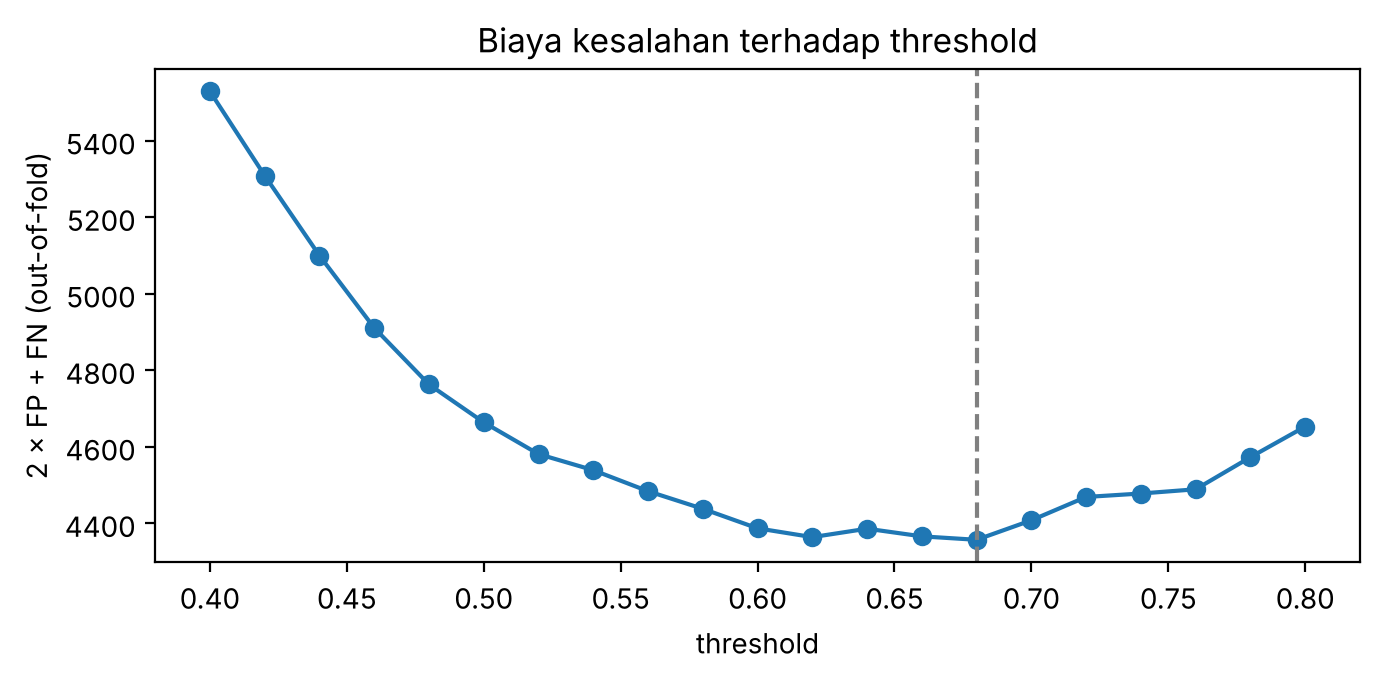

In [35]:
def booking_cost(y_true, predicted):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {'false_positive': fp, 'false_negative': fn, 'cost': 2 * fp + fn,
            'macro_f1': f1_score(y_true, predicted, average='macro')}

cost_thresholds = np.round(np.arange(.40, .801, .02), 2)
cost_table = pd.DataFrame(
    [{'threshold': t, **booking_cost(y_all, (oof_knn >= t).astype(int))} for t in cost_thresholds])
COST_THRESHOLD = float(cost_table.loc[cost_table['cost'].idxmin(), 'threshold'])
print(cost_table.round(4).to_string(index=False))

cost_review = pd.DataFrame({
    f'macro F1 (t={BEST_THRESHOLD})': booking_cost(y_valid, (knn_final.predict_proba(X_val_knn)[:, 1] >= BEST_THRESHOLD).astype(int)),
    f'biaya (t={COST_THRESHOLD})': booking_cost(y_valid, (knn_final.predict_proba(X_val_knn)[:, 1] >= COST_THRESHOLD).astype(int)),
})
print('Validasi:')
print(cost_review.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cost_table['threshold'], cost_table['cost'], marker='o')
ax.axvline(COST_THRESHOLD, linestyle='--', color='gray')
ax.set_xlabel('threshold')
ax.set_ylabel('2 × FP + FN (out-of-fold)')
ax.set_title('Biaya kesalahan terhadap threshold')
fig.tight_layout()
plt.show()

Biaya out-of-fold paling rendah ada pada threshold 0,68, sangat dekat dengan threshold teoretis 2/3. Pada data validasi, menaikkan threshold dari 0,46 ke 0,68 menurunkan false positive dari 301 menjadi 122 dan total biaya dari 960 menjadi 882. Konsekuensinya, false negative bertambah dan macro F1 turun dari 0,862 menjadi 0,828.

Jadi, penanganan berubah pada tahap keputusan, bukan pada model. Untuk kompetisi yang dinilai dengan macro F1, kami tetap memakai threshold 0,46. Jika penginapan lebih mementingkan biaya *overbooking*, model yang sama cukup dipakai dengan threshold sekitar 0,68 sehingga pemesanan baru dianggap batal jika keyakinan model cukup tinggi.

## References

- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [KBinsDiscretizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html)
- [Categorical Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html#categorical-naive-bayes)
- [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)
- J. C. Gower, "A general coefficient of similarity and some of its properties," *Biometrics*, vol. 27, no. 4, pp. 857–871, 1971. [doi:10.2307/2528823](https://doi.org/10.2307/2528823)
- G. E. A. P. A. Batista and M. C. Monard, "An analysis of four missing data treatment methods for supervised learning," *Applied Artificial Intelligence*, vol. 17, no. 5–6, pp. 519–533, 2003. [doi:10.1080/713827181](https://doi.org/10.1080/713827181)
- S. J. Wright, "Coordinate descent algorithms," *Mathematical Programming*, vol. 151, pp. 3–34, 2015. [doi:10.1007/s10107-015-0892-3](https://doi.org/10.1007/s10107-015-0892-3)
- C. Elkan, "The foundations of cost-sensitive learning," in *Proc. IJCAI*, 2001, pp. 973–978.